In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

c:\Users\umaka\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv("../data/smartplate_features.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (21900, 45)


,Date,Day_of_Week,Food_Item,Food_Category,Meal_Type,Quantity_Prepared,Quantity_Sold,Quantity_Wasted,Actual_Demand,Number_of_Students,...,Category_Avg_Waste_Percentage,Meal_Avg_Waste_Percentage,Year,Month,Month_Name,Weekday_Number,Weekday_Name,Is_Weekend,Demand_Per_Student,Demand_Based_Preparation_Buffer
0,2025-01-01,Wednesday,Buttermilk,Beverage,Beverages,41.07,39.09,1.98,39.09,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.227864,1.98
1,2025-01-01,Wednesday,Coffee,Beverage,Beverages,41.47,40.10,1.37,40.10,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.233751,1.37
2,2025-01-01,Wednesday,Lemon Juice,Beverage,Beverages,40.15,37.21,2.94,37.21,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.216905,2.94
3,2025-01-01,Wednesday,Tea,Beverage,Beverages,77.84,57.53,20.31,57.53,171.55,...,6.680912,6.680912,2025,1,January,2,Wednesday,0,0.335354,20.31
4,2025-01-01,Wednesday,Aloo Paratha,Main Course,Breakfast,40.98,39.88,1.10,39.88,171.55,...,6.620998,6.666646,2025,1,January,2,Wednesday,0,0.232469,1.10


In [3]:
print(df.columns.tolist())

['Date', 'Day_of_Week', 'Food_Item', 'Food_Category', 'Meal_Type', 'Quantity_Prepared', 'Quantity_Sold', 'Quantity_Wasted', 'Actual_Demand', 'Number_of_Students', 'Weather', 'Temperature', 'Special_Event_Flag', 'Holiday_Flag', 'Food_Cost_Per_Unit', 'Selling_Price_Per_Unit', 'Estimated_Cost_of_Waste', 'Unmet_Demand', 'Stockout_Flag', 'Waste_Percentage', 'Food_Utilization_Rate', 'Preparation_Buffer', 'Waste_Cost_Per_Unit', 'Total_Revenue', 'Total_Cost', 'Net_Profit', 'Profit_Per_Sold_Unit', 'Food_Cost_Percentage', 'High_Waste_Flag', 'Stockout_Status', 'Temperature_Category', 'Food_Popularity_Group', 'Waste_Severity', 'Revenue_Per_Prepared_Unit', 'Waste_Cost_Ratio', 'Category_Avg_Waste_Percentage', 'Meal_Avg_Waste_Percentage', 'Year', 'Month', 'Month_Name', 'Weekday_Number', 'Weekday_Name', 'Is_Weekend', 'Demand_Per_Student', 'Demand_Based_Preparation_Buffer']


Selecting X and y — Most Important Concept

In [4]:
target = "Actual_Demand"

y = Target Variable

In [5]:
features = [
    "Food_Item",
    "Food_Category",
    "Meal_Type",
    "Day_of_Week",
    "Number_of_Students",
    "Weather",
    "Temperature",
    "Special_Event_Flag",
    "Holiday_Flag",
    "Month",
    "Is_Weekend",
    "Food_Popularity_Group"
]

X = df[features].copy()
y = df[target].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Features Shape: (21900, 12)
Target Shape: (21900,)


,Food_Item,Food_Category,Meal_Type,Day_of_Week,Number_of_Students,Weather,Temperature,Special_Event_Flag,Holiday_Flag,Month,Is_Weekend,Food_Popularity_Group
0,Buttermilk,Beverage,Beverages,Wednesday,171.55,Cloudy,21.2,1,1,1,0,Low
1,Coffee,Beverage,Beverages,Wednesday,171.55,Cloudy,21.2,1,1,1,0,Medium
2,Lemon Juice,Beverage,Beverages,Wednesday,171.55,Cloudy,21.2,1,1,1,0,Low
3,Tea,Beverage,Beverages,Wednesday,171.55,Cloudy,21.2,1,1,1,0,Medium
4,Aloo Paratha,Main Course,Breakfast,Wednesday,171.55,Cloudy,21.2,1,1,1,0,Low


In [6]:
print("Missing values in features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in features:
Food_Item                0
Food_Category            0
Meal_Type                0
Day_of_Week              0
Number_of_Students       0
Weather                  0
Temperature              0
Special_Event_Flag       0
Holiday_Flag             0
Month                    0
Is_Weekend               0
Food_Popularity_Group    0
dtype: int64

Missing values in target:
0


In [7]:
numerical_features = [
    "Number_of_Students",
    "Temperature",
    "Month"
]

categorical_features = [
    "Food_Item",
    "Food_Category",
    "Meal_Type",
    "Day_of_Week",
    "Weather",
    "Food_Popularity_Group"
]

binary_features = [
    "Special_Event_Flag",
    "Holiday_Flag",
    "Is_Weekend"
]

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", drop="first"),
            categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ]
)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (17520, 12)
Testing Data: (4380, 12)


In [10]:
linear_regression_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [11]:
linear_regression_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [12]:
y_pred = linear_regression_model.predict(X_test)

# Food demand cannot be negative, so replace negative predictions with 0
y_pred = np.maximum(y_pred, 0)

print("Predictions generated successfully!")

Predictions generated successfully!


In [13]:
results = pd.DataFrame({
    "Actual_Demand": y_test.values,
    "Predicted_Demand": np.round(y_pred, 2)
})

results.head(10)

,Actual_Demand,Predicted_Demand
0,76.89,101.21
1,111.50,115.78
2,455.25,448.00
3,648.50,612.72
4,117.72,305.67
5,324.17,340.09
6,712.76,565.07
7,12.26,0.00
8,94.37,151.88
9,198.15,274.07


In [14]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

MAE: 47.93
RMSE: 68.42
R²: 0.8828


In [15]:
results.to_csv(
    "../output/linear_regression_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [16]:
import matplotlib.pyplot as plt

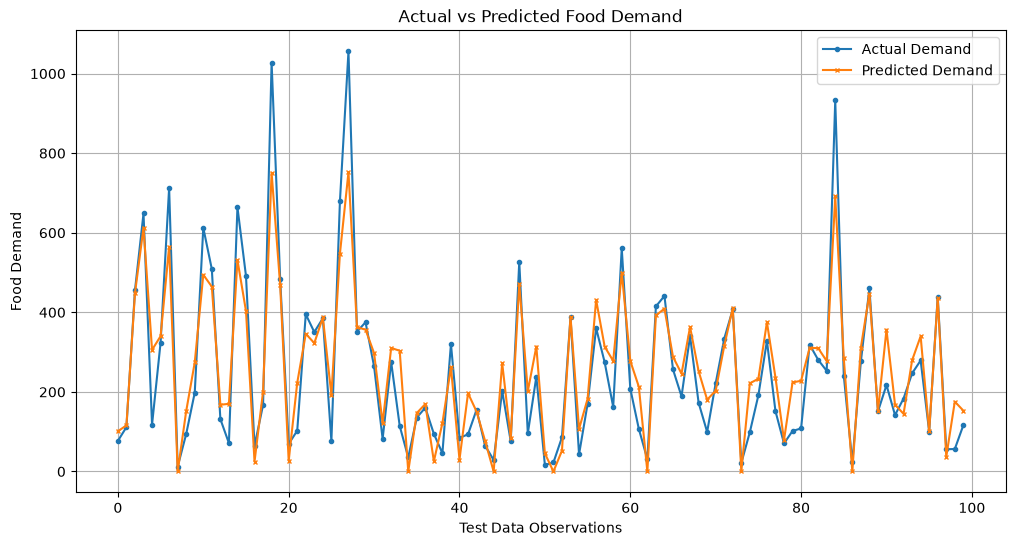

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    results["Actual_Demand"].values[:100],
    label="Actual Demand",
    marker="o",
    markersize=3
)

plt.plot(
    results["Predicted_Demand"].values[:100],
    label="Predicted Demand",
    marker="x",
    markersize=3
)

plt.title("Actual vs Predicted Food Demand")
plt.xlabel("Test Data Observations")
plt.ylabel("Food Demand")
plt.legend()
plt.grid(True)

plt.show()